# 07 - Train and export coastal risk clustering

Input: `data/processed/terengganu_coastal_erosion_transects_144.csv`.
Outputs: `models/kmeans_risk_model_144.joblib` and
`results/kmeans_coastal_risk_results_144.csv`.

Use the same three standardized features, random seed, initialization count and
risk-label mapping as the current application. Compare K=2 through K=6, then use
K=3 to match the application's three risk categories; this choice is not a claim
that K=3 maximizes the silhouette score. Protected stations remain separate.

The original JPS stations and interpolated points participate in clustering.
Comparison with the JPS categories therefore measures agreement on stations
included in training, not accuracy on an independent held-out test set.


In [1]:
from pathlib import Path

# Locate the project from either the repository root or its notebooks folder.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "data" / "raw" / "jps_coastal_erosion_full.csv").is_file():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Open this notebook from inside FYP_Coastal_Erosion.")
    PROJECT_ROOT = PROJECT_ROOT.parent

# Step 1: Load updated dataset

import pandas as pd
import numpy as np

df = pd.read_csv(
    PROJECT_ROOT / "data/processed/terengganu_coastal_erosion_transects_144.csv"
)

# Exclude protected locations
df_model = df[df["Is_Protected"] == 0].copy()

print("=== K-MEANS DATASET ===")
print("Total points:", len(df))
print("Points for K-Means:", len(df_model))
print("Protected points excluded:", df["Is_Protected"].sum())

print("\nTraining data sources:")
print(df_model["Source_Type"].value_counts())
assert df["Transect_ID"].is_unique
assert df.loc[df["Source_Type"].eq("JPS_Original"), "No"].nunique() == 144


=== K-MEANS DATASET ===
Total points: 2775
Points for K-Means: 2766
Protected points excluded: 9

Training data sources:
Source_Type
Interpolated    2631
JPS_Original     135
Name: count, dtype: int64


In [2]:
from sklearn.preprocessing import StandardScaler

# Select features for K-Means
features = [
    "Annual_Erosion_Rate_m_yr",
    "Physical_Erosion_Score",
    "Economic_Score"
]

X = df_model[features].copy()

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("=== K-MEANS FEATURE PREPARATION ===")
print("Feature matrix:", X.shape)
print("Scaled matrix:", X_scaled.shape)

print("\nMissing values:")
print(X.isnull().sum())

print("\nScaled means:")
print(X_scaled.mean(axis=0).round(4))

print("\nScaled standard deviations:")
print(X_scaled.std(axis=0).round(4))

assert X.notna().all().all(), "Missing K-Means inputs"


=== K-MEANS FEATURE PREPARATION ===
Feature matrix: (2766, 3)
Scaled matrix: (2766, 3)

Missing values:
Annual_Erosion_Rate_m_yr    0
Physical_Erosion_Score      0
Economic_Score              0
dtype: int64

Scaled means:
[-0.  0. -0.]

Scaled standard deviations:
[1. 1. 1.]


In [3]:
# Step 3: Test different K values

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 7)

inertia_values = []
silhouette_values = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertia_values.append(model.inertia_)

    score = silhouette_score(
        X_scaled,
        labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

results = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertia_values,
    "Silhouette_Score": silhouette_values
})

print("=== K-MEANS CLUSTER EVALUATION ===")
print(results.round(4))


=== K-MEANS CLUSTER EVALUATION ===
   K    Inertia  Silhouette_Score
0  2  4685.5614            0.4530
1  3  2799.6935            0.4594
2  4  2042.9193            0.4623
3  5  1504.4447            0.4829
4  6  1221.3924            0.4945


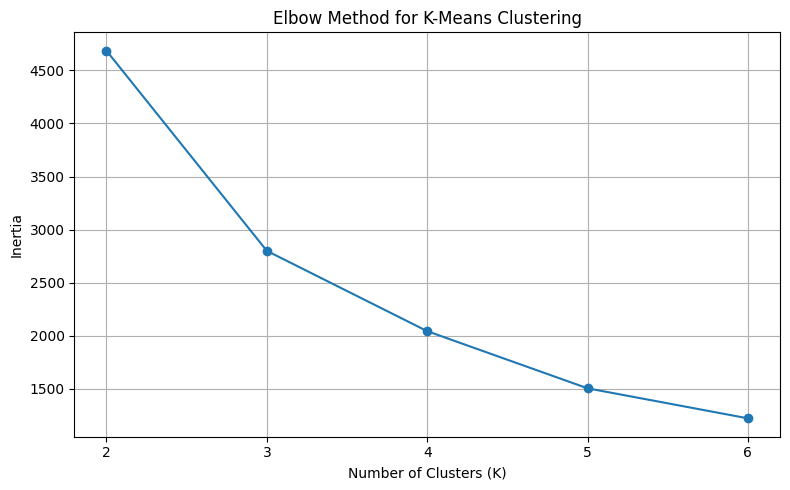

In [4]:
# Step 4: Elbow Method

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for K-Means Clustering")

plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


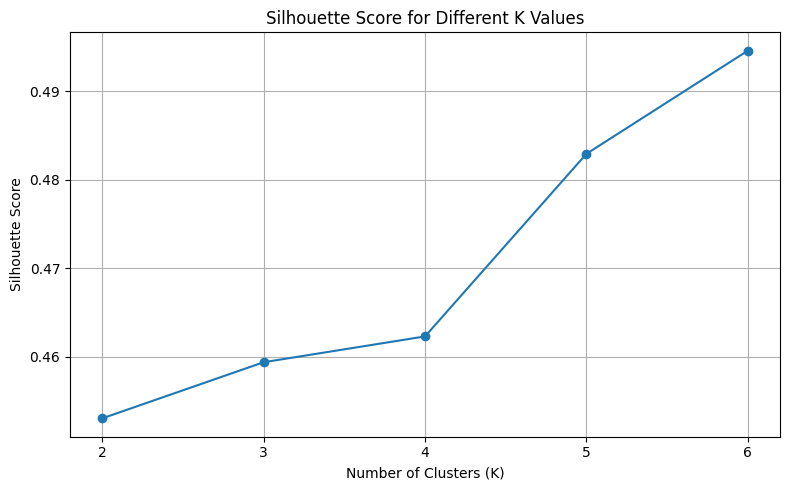

In [5]:
# Step 5: Silhouette Score Graph

plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Different K Values")

plt.xticks(list(k_values))
plt.grid(True)
plt.tight_layout()
plt.show()


In [6]:
# Step 6: Train final K-Means model

from sklearn.cluster import KMeans

# Initialize K-Means with 3 clusters
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

# Train model and assign clusters
df_model["Cluster"] = kmeans.fit_predict(X_scaled)

print("=== FINAL K-MEANS MODEL ===")

print("Number of clusters:", kmeans.n_clusters)
print("Total classified points:", len(df_model))

print("\nCluster distribution:")
print(df_model["Cluster"].value_counts().sort_index())

print("\nModel inertia:", round(kmeans.inertia_, 4))


=== FINAL K-MEANS MODEL ===
Number of clusters: 3
Total classified points: 2766

Cluster distribution:
Cluster
0    1360
1     508
2     898
Name: count, dtype: int64

Model inertia: 2799.6935


In [7]:
# Step 7: Evaluate K-Means performance

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

labels = df_model["Cluster"]

# Calculate evaluation metrics
silhouette = silhouette_score(
    X_scaled,
    labels,
    sample_size=2000,
    random_state=42
)

db_score = davies_bouldin_score(X_scaled, labels)

ch_score = calinski_harabasz_score(X_scaled, labels)

print("=== K-MEANS MODEL EVALUATION ===")

print("Silhouette Score:", round(silhouette, 4))
print("Davies-Bouldin Index:", round(db_score, 4))
print("Calinski-Harabasz Index:", round(ch_score, 2))


=== K-MEANS MODEL EVALUATION ===
Silhouette Score: 0.4594
Davies-Bouldin Index: 0.8438
Calinski-Harabasz Index: 2713.12


In [8]:
# Step 8: Analyze cluster characteristics

cluster_summary = df_model.groupby("Cluster")[
    [
        "Annual_Erosion_Rate_m_yr",
        "Physical_Erosion_Score",
        "Economic_Score",
        "Total_Score_Cleaned"
    ]
].mean()

print("=== CLUSTER CHARACTERISTICS ===")
print(cluster_summary.round(4))

print("\nCluster distribution:")
print(df_model["Cluster"].value_counts().sort_index())


=== CLUSTER CHARACTERISTICS ===
         Annual_Erosion_Rate_m_yr  ...  Total_Score_Cleaned
Cluster                            ...                     
0                          1.8999  ...               2.6894
1                          8.1765  ...               9.5435
2                          1.9859  ...               6.2537

[3 rows x 4 columns]

Cluster distribution:
Cluster
0    1360
1     508
2     898
Name: count, dtype: int64


In [9]:
# Step 9: Assign risk labels to clusters

risk_mapping = {
    0: "Stable",
    1: "Critical",
    2: "Warning"
}

# Assign risk categories
df_model["Risk_Label"] = df_model["Cluster"].map(
    risk_mapping
)

print("=== COASTAL EROSION RISK CLASSIFICATION ===")

print("\nRisk distribution:")
print(
    df_model["Risk_Label"]
    .value_counts()
    .reindex(["Stable", "Warning", "Critical"])
)

print("\nMissing risk labels:")
print(df_model["Risk_Label"].isnull().sum())


=== COASTAL EROSION RISK CLASSIFICATION ===

Risk distribution:
Risk_Label
Stable      1360
Warning      898
Critical     508
Name: count, dtype: int64

Missing risk labels:
0


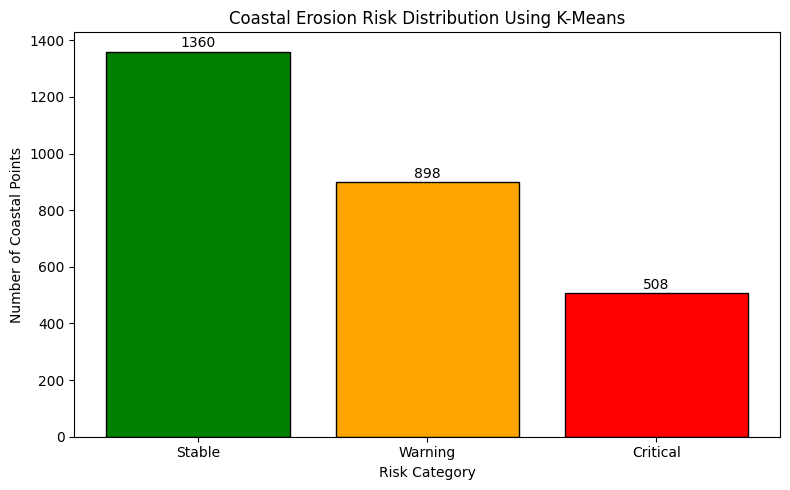

In [10]:
# Step 10: Visualize K-Means risk distribution

risk_counts = (
    df_model["Risk_Label"]
    .value_counts()
    .reindex(["Stable", "Warning", "Critical"])
)

plt.figure(figsize=(8, 5))

bars = plt.bar(
    risk_counts.index,
    risk_counts.values,
    color=["green", "orange", "red"],
    edgecolor="black"
)

# Display counts above bars
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 15,
        str(int(bar.get_height())),
        ha="center"
    )

plt.xlabel("Risk Category")
plt.ylabel("Number of Coastal Points")
plt.title("Coastal Erosion Risk Distribution Using K-Means")

plt.tight_layout()
plt.show()


In [11]:
# Step 11: Compare K-Means with original JPS categories

# Select only original JPS observations
df_jps_eval = df_model[
    df_model["Source_Type"] == "JPS_Original"
].copy()

# Convert JPS categories into numeric codes
df_jps_eval["JPS_Category_Code"] = pd.to_numeric(
    df_jps_eval["ISMP_2022_Category"],
    errors="coerce"
)

# Map official JPS categories to comparable risk labels
jps_mapping = {
    1: "Critical",
    2: "Warning",
    3: "Stable"
}

df_jps_eval["JPS_Risk_Label"] = (
    df_jps_eval["JPS_Category_Code"].map(jps_mapping)
)

print("=== K-MEANS VS JPS COMPARISON ===")

print("Original non-protected JPS stations:",
      len(df_jps_eval))

print("Missing JPS labels:",
      df_jps_eval["JPS_Risk_Label"].isnull().sum())

print("\nOriginal JPS risk distribution:")
print(df_jps_eval["JPS_Risk_Label"].value_counts())

print("\nK-Means risk distribution at JPS stations:")
print(df_jps_eval["Risk_Label"].value_counts())

print("\nComparison table:")
print(pd.crosstab(
    df_jps_eval["JPS_Risk_Label"],
    df_jps_eval["Risk_Label"]
).reindex(
    index=["Stable", "Warning", "Critical"],
    columns=["Stable", "Warning", "Critical"],
    fill_value=0
))


=== K-MEANS VS JPS COMPARISON ===
Original non-protected JPS stations: 135
Missing JPS labels: 0

Original JPS risk distribution:
JPS_Risk_Label
Stable      93
Warning     32
Critical    10
Name: count, dtype: int64

K-Means risk distribution at JPS stations:
Risk_Label
Stable      77
Warning     42
Critical    16
Name: count, dtype: int64

Comparison table:
Risk_Label      Stable  Warning  Critical
JPS_Risk_Label                           
Stable              72       19         2
Warning              5       19         8
Critical             0        4         6


In [12]:
# Step 12: Evaluate agreement with JPS classifications

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report
)

y_true = df_jps_eval["JPS_Risk_Label"]
y_pred = df_jps_eval["Risk_Label"]

correct = (y_true == y_pred).sum()

agreement = accuracy_score(y_true, y_pred) * 100
balanced_agreement = balanced_accuracy_score(y_true, y_pred) * 100

print("=== K-MEANS VS JPS EVALUATION ===")

print("Total JPS stations:", len(df_jps_eval))
print("Correctly matched:", correct)
print("Overall agreement:", round(agreement, 2), "%")
print("Balanced agreement:", round(balanced_agreement, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["Stable", "Warning", "Critical"],
    zero_division=0
))


=== K-MEANS VS JPS EVALUATION ===
Total JPS stations: 135
Correctly matched: 97
Overall agreement: 71.85 %
Balanced agreement: 65.6 %

Classification Report:
              precision    recall  f1-score   support

      Stable       0.94      0.77      0.85        93
     Warning       0.45      0.59      0.51        32
    Critical       0.38      0.60      0.46        10

    accuracy                           0.72       135
   macro avg       0.59      0.66      0.61       135
weighted avg       0.78      0.72      0.74       135



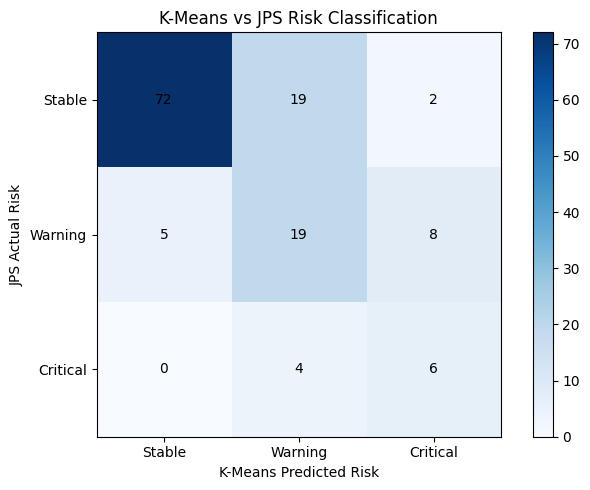

In [13]:
# Step 13: Confusion Matrix

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

categories = ["Stable", "Warning", "Critical"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=categories
)

fig, ax = plt.subplots(figsize=(7, 5))

im = ax.imshow(cm, cmap="Blues")

plt.colorbar(im, ax=ax)

ax.set_xticks(range(3))
ax.set_yticks(range(3))

ax.set_xticklabels(categories)
ax.set_yticklabels(categories)

ax.set_xlabel("K-Means Predicted Risk")
ax.set_ylabel("JPS Actual Risk")
ax.set_title("K-Means vs JPS Risk Classification")

for i in range(3):
    for j in range(3):
        ax.text(
            j, i, cm[i, j],
            ha="center",
            va="center",
            color="black"
        )

plt.tight_layout()
plt.show()


In [14]:
# Step 14: Save updated K-Means model

import os
import joblib

# Create models folder if needed
os.makedirs(PROJECT_ROOT / "models", exist_ok=True)

# Save model, scaler and risk mapping together
model_bundle = {
    "kmeans": kmeans,
    "scaler": scaler,
    "features": features,
    "risk_mapping": risk_mapping
}

# Use a new filename to preserve the previous model
model_path = PROJECT_ROOT / "models/kmeans_risk_model_144.joblib"

joblib.dump(model_bundle, model_path)

# Verify saved model
loaded_bundle = joblib.load(model_path)

print("=== MODEL SAVING ===")
print("K-Means model saved successfully!")
print("File location:", model_path.relative_to(PROJECT_ROOT))
print("Number of clusters:", loaded_bundle["kmeans"].n_clusters)
print("Features:", loaded_bundle["features"])
print("Risk mapping:", loaded_bundle["risk_mapping"])


=== MODEL SAVING ===
K-Means model saved successfully!
File location: models/kmeans_risk_model_144.joblib
Number of clusters: 3
Features: ['Annual_Erosion_Rate_m_yr', 'Physical_Erosion_Score', 'Economic_Score']
Risk mapping: {0: 'Stable', 1: 'Critical', 2: 'Warning'}


In [15]:
# Step 15: Save K-Means classification results

import os
import pandas as pd

# Copy the complete dataset
df_results = df.copy()

# Protected locations remain separate
df_results["Risk_Label"] = "Protected"

# Assign predicted risk categories
df_results.loc[df_model.index, "Risk_Label"] = (
    df_model["Risk_Label"]
)

# Assign cluster numbers
df_results["Cluster"] = pd.Series(
    pd.NA,
    index=df_results.index,
    dtype="Int64"
)

df_results.loc[df_model.index, "Cluster"] = (
    df_model["Cluster"].astype("Int64")
)

assert df_results["Risk_Label"].notna().all()
assert df_results.loc[df_results["Is_Protected"].eq(1), "Risk_Label"].eq("Protected").all()

# Create results folder
os.makedirs(PROJECT_ROOT / "results", exist_ok=True)

# Save without overwriting the previous results
output_path = PROJECT_ROOT / "results/kmeans_coastal_risk_results_144.csv"

df_results.to_csv(output_path, index=False)

print("=== CLASSIFICATION RESULTS ===")
print("Results saved successfully!")
print("File location:", output_path.relative_to(PROJECT_ROOT))

print("\nRisk distribution:")
print(df_results["Risk_Label"].value_counts())

print("\nTotal points:", len(df_results))
print("Missing risk labels:",
      df_results["Risk_Label"].isnull().sum())


=== CLASSIFICATION RESULTS ===
Results saved successfully!
File location: results/kmeans_coastal_risk_results_144.csv

Risk distribution:
Risk_Label
Stable       1360
Warning       898
Critical      508
Protected       9
Name: count, dtype: int64

Total points: 2775
Missing risk labels: 0


In [16]:
# Step 16: Verify saved classification results

df_check = pd.read_csv(
    PROJECT_ROOT / "results/kmeans_coastal_risk_results_144.csv"
)

print("=== FINAL K-MEANS VERIFICATION ===")

print("Total points:", len(df_check))

print("\nRisk distribution:")
print(df_check["Risk_Label"].value_counts())

print("\nMissing risk labels:")
print(df_check["Risk_Label"].isnull().sum())

print("\nOriginal JPS stations:")
print((df_check["Source_Type"] == "JPS_Original").sum())

print("\nTotal points correct:")
print(len(df_check) == 2775)


=== FINAL K-MEANS VERIFICATION ===
Total points: 2775

Risk distribution:
Risk_Label
Stable       1360
Warning       898
Critical      508
Protected       9
Name: count, dtype: int64

Missing risk labels:
0

Original JPS stations:
144

Total points correct:
True
